In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [106]:
data = pd.read_csv("../data/car_fuel_efficiency_2026.csv")

In [8]:
df = data[['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg'
]]

In [9]:
df

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


In [38]:
df.dtypes

engine_displacement      int64
horsepower             float64
vehicle_weight           int64
model_year               int64
fuel_efficiency_mpg    float64
dtype: object

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

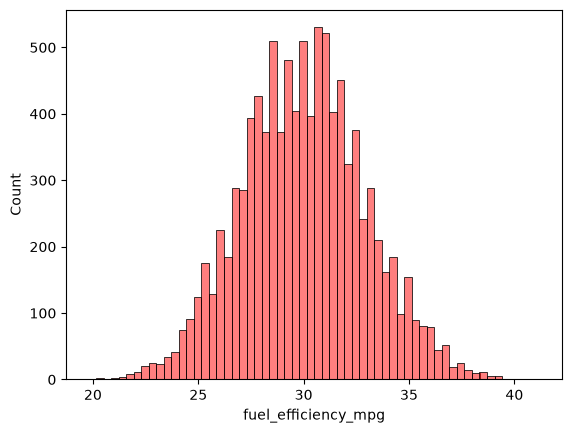

In [27]:
sns.histplot(df['fuel_efficiency_mpg'], color='red', alpha=0.5)

In [29]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [62]:
def prepare_X_fillna_with_zero(df_X):
    df_X = df_X.copy()
    df_X = df_X.fillna(0)
    X = df_X.values
    return X

In [87]:
def prepare_X_fillna_with_mean(df_X):
    df_X = df_X.copy()
    df_X = df_X.fillna(df_train['horsepower'].mean())
    X = df_X.values
    return X

In [71]:
def prepare_y(df_y):
    y = df_y.values
    return y

In [95]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    rmse = np.sqrt(se.mean())
    return rmse

In [32]:
df['horsepower'].median()

np.float64(254.0)

In [66]:
n = len(df)
n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - n_val - n_test

In [67]:
n_train, n_val, n_test

(6000, 2000, 2000)

In [ ]:
np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [84]:
df_X_train = df_train.iloc[:, :-1]
df_y_train = df_train.iloc[: , -1]

df_X_val = df_val.iloc[:, :-1]
df_y_val = df_val.iloc[: , -1]

df_X_test = df_test.iloc[:, :-1]
df_y_test = df_test.iloc[: , -1]

In [70]:
def train_linear_regresstion(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T @ X
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv @ X.T @ y

    return w_full[0], w_full[1:]

In [98]:
# Option 1: fill with 0
X_train = prepare_X_fillna_with_zero(df_X_train)
y_train = prepare_y(df_y_train)

X_val = prepare_X_fillna_with_zero(df_X_val)
y_val = prepare_y(df_y_val)

w0, w = train_linear_regresstion(X_train, y_train)
y_pred = w0 + X_val @ w
round(rmse(y_val, y_pred), 3)


np.float64(2.205)

In [97]:
# Option 2: fill with mean
X_train = prepare_X_fillna_with_mean(df_X_train)
y_train = prepare_y(df_y_train)

X_val = prepare_X_fillna_with_mean(df_X_val)
y_val = prepare_y(df_y_val)

w0, w = train_linear_regresstion(X_train, y_train)
y_pred = w0 + X_val @ w
round(rmse(y_val, y_pred), 3)


np.float64(2.202)

In [90]:
def train_linear_regresstion_reg(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T @ X
    XTX = XTX + r * np.eye(XTX.shape[0])
    
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv @ X.T @ y

    return w_full[0], w_full[1:]

In [96]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X_fillna_with_zero(df_X_train)
    y_train = prepare_y(df_y_train)

    X_val = prepare_X_fillna_with_zero(df_X_val)
    y_val = prepare_y(df_y_val)

    w0, w = train_linear_regresstion_reg(X_train, y_train, r)
    y_pred = w0 + X_val @ w
    score = round(rmse(y_val, y_pred), 4)
    print(r, score)

0 2.2053
0.01 2.2058
0.1 2.2241
1 2.3492
5 2.4094
10 2.4195
100 2.4292


In [102]:
val_rmse = []
for s in range(10):
    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    df_X_train = df_train.iloc[:, :-1]
    df_y_train = df_train.iloc[: , -1]

    df_X_val = df_val.iloc[:, :-1]
    df_y_val = df_val.iloc[: , -1]

    df_X_test = df_test.iloc[:, :-1]
    df_y_test = df_test.iloc[: , -1]

    # Option 1: fill with 0
    X_train = prepare_X_fillna_with_zero(df_X_train)
    y_train = prepare_y(df_y_train)

    X_val = prepare_X_fillna_with_zero(df_X_val)
    y_val = prepare_y(df_y_val)

    w0, w = train_linear_regresstion(X_train, y_train)
    y_pred = w0 + X_val @ w
    score = rmse(y_val, y_pred)

    val_rmse.append(score)

val_rmse = np.array(val_rmse)
std_val_rmse = round(np.std(val_rmse), 3)


In [103]:
std_val_rmse

np.float64(0.029)

In [104]:
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

df_X_train = df_train.iloc[:, :-1]
df_y_train = df_train.iloc[: , -1]

df_X_val = df_val.iloc[:, :-1]
df_y_val = df_val.iloc[: , -1]

df_X_test = df_test.iloc[:, :-1]
df_y_test = df_test.iloc[: , -1]

df_X_full_train = pd.concat([df_X_train, df_X_val])
df_y_full_train = pd.concat([df_y_train, df_y_val])

# Option 1: fill with 0
X_full_train = prepare_X_fillna_with_zero(df_X_full_train)
y_full_train = prepare_y(df_y_full_train)

X_test = prepare_X_fillna_with_zero(df_X_test)
y_test = prepare_y(df_y_test)

w0, w = train_linear_regresstion_reg(X_full_train, y_full_train, r=0.001)
y_pred = w0 + X_test @ w
score = rmse(y_test, y_pred)

In [105]:
score

np.float64(2.235827747196414)